# WaveGrip: Gesture Classification CNN
## ResNet-152 v1.5 (no skip connections) on the Raw sEMG wrist dataset

Tristan Au

This notebook trains and evaluates a CNN that classifies the 17 GRABMyo gestures from the **Raw sEMG** representation built by `Preprocessing/grabmyo_build_datasets.ipynb`. It is one of three notebooks (`cnn_dwt.ipynb`, `cnn_psd.ipynb`, and this one) that use **the same model**. Only the input layer differs.

The model copies the **ResNet-152 v1.5** architecture (He et al., 2016; v1.5 = the torchvision / NVIDIA variant with the stride-2 downsampling in the 3×3 convolution of each bottleneck) **without its skip connections**. Each bottleneck block is 1×1 conv → BN → ReLU → 3×3 conv → BN → ReLU → 1×1 conv → BN → ReLU, and nothing is added back from the block's input. The only other changes are a 1-channel input instead of 3 (RGB), and 17 outputs instead of 1000.

| Stage | Layers | Output shape (C × H × W) |
|---|---|---|
| Input | 12 wrist electrodes × 10240 time samples (the whole 5 s trial at 2048 Hz) | 1 × 12 × 10240 |
| Stem (conv1) | Conv 7×7, 64, stride 2 → BN → ReLU → MaxPool 3×3, stride 2 | 64 × 3 × 2560 |
| layer1 | 3 bottlenecks [1×1, 64 → 3×3, 64 → 1×1, 256] | 256 × 3 × 2560 |
| layer2 | 8 bottlenecks [1×1, 128 → 3×3, 128 → 1×1, 512], first 3×3 has stride 2 | 512 × 2 × 1280 |
| layer3 | 36 bottlenecks [1×1, 256 → 3×3, 256 → 1×1, 1024], first 3×3 has stride 2 | 1024 × 1 × 640 |
| layer4 | 3 bottlenecks [1×1, 512 → 3×3, 512 → 1×1, 2048], first 3×3 has stride 2 | 2048 × 1 × 320 |
| Global average pooling | mean over the remaining H × W | 2048 |
| FC | Linear 2048 → 17 | 17 |
| Softmax → output | (log-)softmax over the 17 gestures | 17 |

That is 1 + 3 × (3 + 8 + 36 + 3) = 151 convolution layers + 1 FC layer = **152 weight layers**, with 55.4 M parameters.

**About removing the skip connections.** Without skip connections this is a *plain* 152-layer network. He et al. (2016) showed that plain networks this deep reach **higher training error** than shallower ones (the "degradation problem"), and that problem is what skip connections were introduced to fix. To keep it trainable, the network uses ResNet's Kaiming initialisation and BatchNorm after every convolution. Setting `USE_SKIP_CONNECTIONS = True` in Section 0 gives the standard ResNet-152 v1.5, with identity shortcuts and 1×1-conv projection shortcuts where the shape changes, for comparison. The two variants are trained separately and save their weights, training curves and history to separate folders and file names (see below), so they can be compared later.

### Running on Google Colab (free T4 GPU)

1. In Google Drive, create `MyDrive/WaveGrip/ProcessedDatasets/raw_wrist/` and upload `grabmyo_wrist_raw.h5` into it. Upload this notebook anywhere.
2. Open the notebook in Colab: **Runtime → Change runtime type → T4 GPU**.
3. Run all cells. The configuration cell mounts Drive and copies the dataset to the Colab machine's local disk, because reading straight from Drive is slow. Results and weights go to `MyDrive/WaveGrip/CNN/runs/`, so they outlive the Colab session.

The same notebook also runs locally from `CNN/` (CPU or GPU) with no changes.

**GPU optimisations:**
- The whole dataset sits in GPU memory, so no data is copied between CPU and GPU during training.
- Mixed precision (`torch.autocast` float16 + `GradScaler`) uses the T4's tensor cores.
- The model uses the `channels_last` memory layout.
- `cudnn.benchmark` picks the fastest convolution algorithms.

### Train once, then reuse

Each variant has its own fixed run folder, and every file in it starts with the run name, so the files stay identifiable when copied elsewhere:

| `USE_SKIP_CONNECTIONS` | Run folder and file prefix |
|---|---|
| `False` (no skips) | `runs/raw_<split>_resnet152_noskip/raw_<split>_resnet152_noskip_*` |
| `True` (skips) | `runs/raw_<split>_resnet152/raw_<split>_resnet152_*` |

- **Weights already saved:** if the run's `*_state_dict.pt` exists, the notebook **loads it and skips training**. Set `RETRAIN = True` to train again.
- **Resuming:** a full training checkpoint is saved after **every epoch**. If Colab disconnects mid-training, re-running the notebook resumes from the last finished epoch.
- **Comparing the variants:** run the notebook once with `USE_SKIP_CONNECTIONS = False` and once with `True`. Each run keeps its own weights (`*_state_dict.pt`), training curves (`*_curves.png`) and per-epoch history (`*_history.csv`).
- **Reloading later:** Section 7 shows how to load the saved weights in a new session and checks that they reproduce the trained model.

**Side Notes:**

**Input layer.** Each trial goes in as a one-channel 2D "image": the 12 wrist electrodes (W1–W12) on the height axis and the representation's own axis on the width. Input normalisation: mV, z-scored per channel (training-set mean/std). ResNet's five stride-2 stages reduce the 12 electrode rows to 1 by layer3, and the width 32× (10240 → 320). Global average pooling makes the rest of the network independent of the input width, so all three notebooks have exactly the same layers and the same number of parameters.

**Softmax.** The last layer is `LogSoftmax`, trained with `NLLLoss`. Together these equal softmax followed by cross-entropy, but they are numerically stable. The class probabilities are `exp(output)`.

**Split.** The data is first split into **training and testing** sets (`TEST_FRACTION` = 20 %). The training set is then split again into **training and validation** sets (`VAL_FRACTION` = 20 % of training). That gives 64 / 16 / 20 % overall. `"random"` is within-participant and stratified by participant × gesture. `"participant"` holds out whole participants at both steps, for a cross-participant test. The three datasets store trials in the same row order and the split uses a fixed seed, so all three notebooks and both variants use the same train, validation and test trials.

**Epochs.** Training runs for **10–50 epochs**. It always runs `MIN_EPOCHS` = 10, then stops early once validation loss has not improved for `PATIENCE` epochs, and never goes past `MAX_EPOCHS` = 50. The weights from the epoch with the lowest validation loss are kept. The learning rate is halved when validation loss plateaus for 3 epochs.

**Test set.** This notebook **never uses the test set**. Training uses the training split, and model selection and early stopping use the validation split. Testing happens elsewhere. The test row indices are saved in `*_split.npz` and the normalisation statistics in `*_normalization.npz`, so the evaluation code can rebuild exactly the same test inputs.

**Memory.** The raw counts are kept as int16 (3.8 GB) **in GPU memory** and turned into normalised float32 one batch at a time, so no data moves between CPU and GPU during training. ResNet-152 needs ~0.4–0.5 GB of float16 activations per raw trial during training, so the batch is 8 (≈ 9–10 GB peak on the 15 GB T4). If it runs out of memory, lower `BATCH_SIZE`; if there is room to spare, try 12–16.

## 0. Configuration

In [2]:
import csv
import gc
import json
import os
import shutil
import sys
import time
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import torch
from matplotlib.ticker import MaxNLocator
from sklearn.model_selection import train_test_split
from torch import nn

REPRESENTATION = "raw"
DATA_FILE = "raw_wrist/grabmyo_wrist_raw.h5"                # relative to ProcessedDatasets/

# ---- Paths: Google Colab (Drive) or the local project folder --------------------------------------
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_ROOT = Path("/content/drive/MyDrive/WaveGrip")    # same layout as the local project folder
    drive_h5 = PROJECT_ROOT / "ProcessedDatasets" / DATA_FILE
    assert drive_h5.exists(), f"upload the dataset to {drive_h5}"
    H5_PATH = Path("/content/data") / DATA_FILE                # Drive reads are slow: copy once per session
    if not H5_PATH.exists() or H5_PATH.stat().st_size != drive_h5.stat().st_size:
        H5_PATH.parent.mkdir(parents=True, exist_ok=True)
        t0 = time.perf_counter()
        shutil.copyfile(drive_h5, H5_PATH)
        print(f"copied {drive_h5.name} to local disk in {time.perf_counter() - t0:.0f} s")
else:
    PROJECT_ROOT = Path.cwd().parent                           # run from CNN/
    H5_PATH = PROJECT_ROOT / "ProcessedDatasets" / DATA_FILE
assert H5_PATH.exists(), f"dataset not found at {H5_PATH}"
RUN_ROOT = PROJECT_ROOT / "CNN" / "runs"                       # on Drive in Colab, so weights outlive the session

# ---- Device and GPU settings ----------------------------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"                  # float16 mixed precision on the T4's tensor cores
STORE_DTYPE = torch.float16 if device.type == "cuda" else torch.float32   # dtype of float inputs kept on device
if device.type == "cuda":
    torch.backends.cudnn.benchmark = True        # pick the fastest conv algorithms for the fixed input shape
elif IN_COLAB:
    print("WARNING: no GPU. In Colab use Runtime -> Change runtime type -> T4 GPU")

N_CLASSES = 17                          # gestures 1-17 -> classes 0-16
INPUT_SHAPE = (1, 12, 10240)            # (image channels, electrodes, width)

# ---- Model: ResNet-152 v1.5 (shared by all three notebooks) ---------------------------------------
RESNET_LAYERS = (3, 8, 36, 3)           # bottleneck blocks in layer1-4 (ResNet-152)
RESNET_WIDTHS = (64, 128, 256, 512)     # bottleneck widths; block output = 4 x width
USE_SKIP_CONNECTIONS = True            # False: plain network, no skip connections; True: standard ResNet-152

# ---- Split: train/test first, then train -> train/val ---------------------------------------------
SPLIT = "random"                        # "random" (within-participant) or "participant" (cross-participant)
TEST_FRACTION = 0.2
VAL_FRACTION = 0.2                      # fraction of the training set

# ---- Training: 10-50 epochs with early stopping on validation loss --------------------------------
MIN_EPOCHS = 10
MAX_EPOCHS = 50
PATIENCE = 8                            # epochs without val-loss improvement (checked after MIN_EPOCHS)
BATCH_SIZE = 8 if device.type == "cuda" else 2
LR = 1e-3
WEIGHT_DECAY = 1e-4
LR_FACTOR, LR_PATIENCE = 0.5, 3         # ReduceLROnPlateau on validation loss
SEED = 0
CHUNK = 512                             # rows per chunk when computing normalisation statistics

# ---- Saving / reusing the trained model -----------------------------------------------------------
RETRAIN = False                         # False: load saved weights if they exist (train once); True: train again
# Writes model_state_dict.pt (trained weights) and checkpoint.pt (resumable training state)

MODEL_NAME = "resnet152" + ("" if USE_SKIP_CONNECTIONS else "_noskip")
RUN_NAME = f"{REPRESENTATION}_{SPLIT}_{MODEL_NAME}"      # e.g. psd_random_resnet152_noskip
RUN_DIR = RUN_ROOT / RUN_NAME                                # fixed name, so a finished run is found again
RUN_DIR.mkdir(parents=True, exist_ok=True)

torch.manual_seed(SEED)
gpu = f" ({torch.cuda.get_device_name(0)})" if device.type == "cuda" else ""
print(f"{REPRESENTATION}: {H5_PATH}\ndevice {device}{gpu}, AMP {USE_AMP}, batch {BATCH_SIZE}, "
      f"torch {torch.__version__}\nrun folder: {RUN_DIR}")

Mounted at /content/drive
copied grabmyo_wrist_raw.h5 to local disk in 129 s
raw: /content/data/raw_wrist/grabmyo_wrist_raw.h5
device cuda (Tesla T4), AMP True, batch 8, torch 2.14.1+cu130
run folder: /content/drive/MyDrive/WaveGrip/CNN/runs/raw_random_resnet152


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Trial index and split

The index arrays (`session`, `participant`, `gesture`, `trial`) are the same in all three dataset files. **Step 1:** split all trials into training and testing. **Step 2:** split the training trials again into training and validation. The test set is never used in this notebook; its indices are saved for evaluation elsewhere (Section 6).

In [4]:
with h5py.File(H5_PATH) as f:
    meta = {k: f[k][:].astype(np.int64) for k in ["session", "participant", "gesture", "trial"]}
labels = meta["gesture"] - 1


def holdout(rows, fraction, scheme, seed):
    # Split `rows` into (keep, held_out)
    if scheme == "random":                                   # stratified by participant x gesture
        strata = meta["participant"][rows] * 100 + meta["gesture"][rows]
        return train_test_split(rows, test_size=fraction, stratify=strata, random_state=seed)
    if scheme == "participant":                              # hold out whole participants
        people = np.unique(meta["participant"][rows])
        n_out = max(1, round(fraction * len(people)))
        out_p = np.random.default_rng(seed).choice(people, n_out, replace=False)
        mask = np.isin(meta["participant"][rows], out_p)
        return rows[~mask], rows[mask]
    raise ValueError(f"unknown split scheme {scheme!r}")


all_rows = np.arange(len(labels))
trainval_rows, test_rows = holdout(all_rows, TEST_FRACTION, SPLIT, SEED)          # step 1: train / test
train_rows, val_rows = holdout(trainval_rows, VAL_FRACTION, SPLIT, SEED + 1)      # step 2: train / val
split = {"train": np.sort(train_rows), "val": np.sort(val_rows), "test": np.sort(test_rows)}

assert not (set(split["train"]) & set(split["val"]) or set(split["train"]) & set(split["test"])
            or set(split["val"]) & set(split["test"]))
for k, v in split.items():
    print(f"{k:>5}: {len(v):5d} trials ({100 * len(v) / len(labels):4.1f} %), "
          f"{len(np.unique(meta['participant'][v]))} participants, "
          f"trials per gesture {np.bincount(labels[v], minlength=N_CLASSES).min()}-"
          f"{np.bincount(labels[v], minlength=N_CLASSES).max()}")

train:  9824 trials (64.0 %), 43 participants, trials per gesture 573-582
  val:  2456 trials (16.0 %), 43 participants, trials per gesture 139-149
 test:  3071 trials (20.0 %), 43 participants, trials per gesture 178-185


## 2. Input layer: load and normalise the Raw sEMG data

Normalisation: mV, z-scored per channel (training-set mean/std). The statistics come **from the training rows only**, so nothing from validation or test leaks into training. They are saved with the model (`*_normalization.npz`) so the test set and any new data can be normalised the same way. The data is then moved to `device` (the GPU in Colab) once, and every batch is built there.

In [5]:
def channel_mean_std(get_rows, rows, axis):
    # Mean/std over `axis`, accumulated in float64 over chunks of `rows`
    s = ss = n = 0
    for i in range(0, len(rows), CHUNK):
        x = get_rows(rows[i:i + CHUNK]).astype(np.float64)
        s = s + x.sum(axis=axis)
        ss = ss + (x ** 2).sum(axis=axis)
        n += x.size // np.prod(s.shape)
    mean = s / n
    std = np.sqrt(np.maximum(ss / n - mean ** 2, 0))
    return mean, np.where(std > 0, std, 1.0)

In [6]:
class RawInputs:
    """int16 counts kept on DEVICE; each batch -> normalised float32 via counts * a + b."""

    def __init__(self, train_idx):
        with h5py.File(H5_PATH) as f:
            counts = f["emg"][:]                                        # (N, 12, 10240) int16, 3.8 GB
            gain, baseline = f["gain"][:], f["baseline"][:].astype(np.float64)
        to_mv = lambda r: (counts[r] - baseline[r][..., None]) / gain[r][..., None]
        mean, std = channel_mean_std(to_mv, train_idx, axis=(0, 2))     # per channel, in mV
        self.norm = {"mean_mV": mean, "std_mV": std}                    # saved with the model
        # ((counts - baseline) / gain - mean) / std  ==  counts * a + b
        self.a = torch.from_numpy((1.0 / (gain * std)).astype(np.float32)).to(device)
        self.b = torch.from_numpy((-(baseline / gain + mean) / std).astype(np.float32)).to(device)
        self.counts = torch.from_numpy(counts).to(device)

    def get(self, rows):
        x = self.counts[rows].float() * self.a[rows][..., None] + self.b[rows][..., None]
        return x.unsqueeze(1)                                           # (B, 1, 12, 10240)


t0 = time.perf_counter()
inputs = RawInputs(split["train"])
gc.collect()
print(f"Raw inputs on {device} in {time.perf_counter() - t0:.0f} s: {tuple(inputs.counts.shape)} {inputs.counts.dtype}")

Raw inputs on cuda in 34 s: (15351, 12, 10240) torch.int16


In [7]:
labels_t = torch.from_numpy(labels).to(device)
split_t = {k: torch.from_numpy(v) for k, v in split.items()}          # row indices stay on the CPU


def iterate_batches(rows, batch_size, shuffle=False, generator=None):
    # Yield (x, y) on device: x (B, 1, 12, W) float32, y (B,) int64 class ids 0-16
    if shuffle:
        rows = rows[torch.randperm(len(rows), generator=generator)]
    for i in range(0, len(rows), batch_size):
        r = rows[i:i + batch_size].to(device)
        x = inputs.get(r)
        if device.type == "cuda":
            x = x.contiguous(memory_format=torch.channels_last)
        yield x, labels_t[r]


x_check, _ = next(iterate_batches(split_t["train"], 256, shuffle=True, generator=torch.Generator().manual_seed(1)))
assert tuple(x_check.shape[1:]) == INPUT_SHAPE, x_check.shape
print(f"batch {tuple(x_check.shape)} on {x_check.device}: mean {x_check.mean():.3f}, std {x_check.std():.3f}")
del x_check

batch (256, 1, 12, 10240) on cuda:0: mean 0.000, std 1.031


## 3. Model: ResNet-152 v1.5 without skip connections

This cell is identical in all three notebooks. The layer names follow torchvision's `resnet152` (`conv1`, `bn1`, `layer1`–`layer4`, `fc`).

- **Initialisation** is the same as ResNet's: Kaiming-normal convolutions (fan-out, ReLU), BatchNorm weights 1 and biases 0.
- **With `USE_SKIP_CONNECTIONS = True`**, each block adds its input back before the last ReLU, through a 1×1-conv + BN projection where the stride or channel count changes. That is exactly torchvision's ResNet-152 v1.5 apart from the input channels and the number of classes.
- **Output:** the last layer is `LogSoftmax`, so the output is log-probabilities over the 17 gestures.

In [8]:
class Bottleneck(nn.Module):
    """ResNet v1.5 bottleneck: 1x1 -> 3x3 (carries the stride) -> 1x1 (4x width), each followed by BN."""
    expansion = 4

    def __init__(self, in_ch, width, stride=1, skip=USE_SKIP_CONNECTIONS):
        super().__init__()
        out_ch = width * self.expansion
        self.conv1 = nn.Conv2d(in_ch, width, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(width)
        self.conv2 = nn.Conv2d(width, width, 3, stride=stride, padding=1, bias=False)   # v1.5: stride on the 3x3
        self.bn2 = nn.BatchNorm2d(width)
        self.conv3 = nn.Conv2d(width, out_ch, 1, bias=False)
        self.bn3 = nn.BatchNorm2d(out_ch)
        self.relu = nn.ReLU(inplace=True)
        self.skip = skip
        self.downsample = None
        if skip and (stride != 1 or in_ch != out_ch):                  # projection shortcut (skip variant only)
            self.downsample = nn.Sequential(nn.Conv2d(in_ch, out_ch, 1, stride=stride, bias=False),
                                            nn.BatchNorm2d(out_ch))

    def forward(self, x):
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.relu(self.bn2(self.conv2(out)))
        out = self.bn3(self.conv3(out))
        if self.skip:                                                  # off by default: no skip connection
            out = out + (x if self.downsample is None else self.downsample(x))
        return self.relu(out)


class ResNet152(nn.Module):
    def __init__(self, in_ch=INPUT_SHAPE[0], n_classes=N_CLASSES, layers=RESNET_LAYERS, widths=RESNET_WIDTHS,
                 skip=USE_SKIP_CONNECTIONS):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, 64, 7, stride=2, padding=3, bias=False)
        self.bn1 = nn.BatchNorm2d(64)
        self.relu = nn.ReLU(inplace=True)
        self.maxpool = nn.MaxPool2d(3, stride=2, padding=1)
        ch, stages = 64, []
        for i, (n_blocks, width) in enumerate(zip(layers, widths)):
            blocks = []
            for b in range(n_blocks):
                blocks.append(Bottleneck(ch, width, stride=2 if (i > 0 and b == 0) else 1, skip=skip))
                ch = width * Bottleneck.expansion
            stages.append(nn.Sequential(*blocks))
        self.layer1, self.layer2, self.layer3, self.layer4 = stages
        self.avgpool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(ch, n_classes)
        self.log_softmax = nn.LogSoftmax(dim=1)     # softmax output (log form); probabilities = exp(output)
        for m in self.modules():                    # ResNet initialisation
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)

    def stem(self, x):
        return self.maxpool(self.relu(self.bn1(self.conv1(x))))

    def forward(self, x):
        x = self.layer4(self.layer3(self.layer2(self.layer1(self.stem(x)))))
        return self.log_softmax(self.fc(torch.flatten(self.avgpool(x), 1)))


def build_model():
    return ResNet152()


model = build_model().to(device)
if device.type == "cuda":
    model = model.to(memory_format=torch.channels_last)

model.eval()
with torch.no_grad():                               # feature-map shape after each stage
    x = model.stem(torch.zeros(2, *INPUT_SHAPE, device=device))
    shapes = {"stem": tuple(x.shape[1:])}
    for name in ["layer1", "layer2", "layer3", "layer4"]:
        x = getattr(model, name)(x)
        shapes[name] = tuple(x.shape[1:])
n_conv = sum(isinstance(m, nn.Conv2d) for m in model.modules())
print(f"{MODEL_NAME}: skip connections {USE_SKIP_CONNECTIONS}, {n_conv} conv layers + 1 FC, "
      f"parameters {sum(p.numel() for p in model.parameters()):,}")
for name, shp in shapes.items():
    print(f"  {name:>6}: {shp}")

resnet152: skip connections True, 155 conv layers + 1 FC, parameters 58,172,369
    stem: (64, 3, 2560)
  layer1: (256, 3, 2560)
  layer2: (512, 2, 1280)
  layer3: (1024, 1, 640)
  layer4: (2048, 1, 320)


## 4. Training

The model is trained with Adam and `NLLLoss` on the log-softmax output, using float16 mixed precision on the GPU. Each epoch records:

- training and validation loss and accuracy;
- training time and validation time.

The weights with the lowest validation loss are kept. Early stopping can only trigger after `MIN_EPOCHS`, and training is capped at `MAX_EPOCHS`.

What happens when this section runs:

| State of `RUN_DIR` | What happens |
|---|---|
| `*_state_dict.pt` exists, `RETRAIN = False` | **No training.** The saved weights and history are loaded. |
| only `*_checkpoint.pt` exists (session ended mid-training) | Training **resumes** after the last finished epoch, restoring the model, optimizer, LR scheduler, AMP scaler, shuffling RNG and history. |
| nothing saved, or `RETRAIN = True` | Training from scratch. |

`*_checkpoint.pt` is overwritten after every epoch, written to a temporary file and then renamed so it is never left half-written. `*_state_dict.pt` and `*_history.csv` are written once training ends.

In [9]:
loss_fn = nn.NLLLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=LR_FACTOR, patience=LR_PATIENCE)
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
shuffle_gen = torch.Generator().manual_seed(SEED)

# Every output file is prefixed with the run name, so the two variants never overwrite each other
STATE_PATH = RUN_DIR / f"{RUN_NAME}_state_dict.pt"         # learned weights + biases (best validation epoch)
CKPT_PATH = RUN_DIR / f"{RUN_NAME}_checkpoint.pt"          # full training state, for resuming
HISTORY_PATH = RUN_DIR / f"{RUN_NAME}_history.csv"         # per-epoch training curves (numbers)
CURVES_PATH = RUN_DIR / f"{RUN_NAME}_curves.png"           # training curves (figure)
NORM_PATH = RUN_DIR / f"{RUN_NAME}_normalization.npz"
SPLIT_PATH = RUN_DIR / f"{RUN_NAME}_split.npz"
INFO_PATH = RUN_DIR / f"{RUN_NAME}_info.json"


def sync():
    if device.type == "cuda":
        torch.cuda.synchronize()                                   # accurate timing of async GPU work


@torch.no_grad()
def evaluate(model, rows):
    model.eval()
    total_loss, preds, trues = 0.0, [], []
    for x, y in iterate_batches(rows, BATCH_SIZE):
        with torch.autocast(device.type, dtype=torch.float16, enabled=USE_AMP):
            log_probs = model(x)
        total_loss += loss_fn(log_probs.float(), y).item() * len(y)
        preds.append(log_probs.argmax(1).cpu())
        trues.append(y.cpu())
    preds, trues = torch.cat(preds).numpy(), torch.cat(trues).numpy()
    return total_loss / len(trues), (preds == trues).mean(), preds, trues


def train_one_epoch(model):
    model.train()
    run_loss = torch.zeros((), device=device)
    run_correct = torch.zeros((), device=device, dtype=torch.long)
    n_seen = 0
    for x, y in iterate_batches(split_t["train"], BATCH_SIZE, shuffle=True, generator=shuffle_gen):
        with torch.autocast(device.type, dtype=torch.float16, enabled=USE_AMP):
            log_probs = model(x)
            loss = loss_fn(log_probs.float(), y)
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        run_loss += loss.detach() * len(y)                        # stays on the GPU: no sync per batch
        run_correct += (log_probs.argmax(1) == y).sum()
        n_seen += len(y)
    return run_loss.item() / n_seen, run_correct.item() / n_seen


def save_checkpoint(epoch, finished):
    ckpt = dict(epoch=epoch, finished=finished, model=model.state_dict(), optimizer=optimizer.state_dict(),
                scheduler=scheduler.state_dict(), scaler=scaler.state_dict(), shuffle_rng=shuffle_gen.get_state(),
                history=history, best_state=best_state, best_epoch=best_epoch, best_val_loss=best_val_loss)
    tmp = CKPT_PATH.with_suffix(".tmp")
    torch.save(ckpt, tmp)
    os.replace(tmp, CKPT_PATH)


def write_history(history):
    with open(HISTORY_PATH, "w", newline="") as fh:
        w = csv.DictWriter(fh, fieldnames=list(history[0]))
        w.writeheader()
        w.writerows(history)


def read_history():
    with open(HISTORY_PATH, newline="") as fh:
        return [{k: (int(v) if k == "epoch" else float(v)) for k, v in r.items()} for r in csv.DictReader(fh)]

In [10]:
history, best_val_loss, best_epoch, best_state, start_epoch, finished = [], float("inf"), 0, None, 1, False

if STATE_PATH.exists() and not RETRAIN:                       # ---- trained before: load, skip training
    best_state = torch.load(STATE_PATH, map_location="cpu", weights_only=True)
    history = read_history()
    best_epoch = min(history, key=lambda h: h["val_loss"])["epoch"]
    best_val_loss = history[best_epoch - 1]["val_loss"]
    finished = True
    print(f"Loaded trained weights from {STATE_PATH.name} (best epoch {best_epoch} of {len(history)}); "
          f"training skipped. Set RETRAIN = True to train again.")
elif CKPT_PATH.exists() and not RETRAIN:                      # ---- interrupted run: resume
    ckpt = torch.load(CKPT_PATH, map_location=device, weights_only=True)
    model.load_state_dict(ckpt["model"])
    optimizer.load_state_dict(ckpt["optimizer"])
    scheduler.load_state_dict(ckpt["scheduler"])
    scaler.load_state_dict(ckpt["scaler"])
    shuffle_gen.set_state(ckpt["shuffle_rng"])
    history, best_state = ckpt["history"], ckpt["best_state"]
    best_epoch, best_val_loss, finished = ckpt["best_epoch"], ckpt["best_val_loss"], ckpt["finished"]
    start_epoch = ckpt["epoch"] + 1
    print(f"Resuming from checkpoint after epoch {ckpt['epoch']}" + (" (already finished)" if finished else ""))
    del ckpt
else:
    print("Training from scratch")

for epoch in range(start_epoch, MAX_EPOCHS + 1):
    if finished:
        break
    sync(); t0 = time.perf_counter()
    train_loss, train_acc = train_one_epoch(model)
    sync(); t1 = time.perf_counter()
    val_loss, val_acc, _, _ = evaluate(model, split_t["val"])
    sync(); t2 = time.perf_counter()
    lr = optimizer.param_groups[0]["lr"]
    scheduler.step(val_loss)
    row = dict(lr=lr, train_loss=train_loss, train_acc=train_acc, val_loss=val_loss, val_acc=val_acc,
               train_s=t1 - t0, val_s=t2 - t1)
    history.append({"epoch": epoch, **{k: float(v) for k, v in row.items()}})   # plain floats: checkpoint loads with weights_only=True
    improved = val_loss < best_val_loss
    if improved:
        best_val_loss, best_epoch = val_loss, epoch
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    finished = epoch == MAX_EPOCHS or (epoch >= MIN_EPOCHS and epoch - best_epoch >= PATIENCE)
    save_checkpoint(epoch, finished)
    print(f"epoch {epoch:2d}  loss train {train_loss:.4f} val {val_loss:.4f}  |  "
          f"acc train {train_acc:.4f} val {val_acc:.4f}  |  "
          f"train {t1 - t0:5.1f} s, val {t2 - t1:4.1f} s{'  *' if improved else ''}")
    if finished and epoch < MAX_EPOCHS:
        print(f"early stop: no validation-loss improvement for {PATIENCE} epochs")

model.load_state_dict(best_state)                              # keep the best-validation weights
if not STATE_PATH.exists() or RETRAIN:
    torch.save(best_state, STATE_PATH)                         # the trained weights, saved once
    write_history(history)
    print(f"saved {STATE_PATH}")

train_time = sum(h["train_s"] for h in history)
total_time = train_time + sum(h["val_s"] for h in history)
best = history[best_epoch - 1]
print(f"{RUN_NAME}: {len(history)} epochs, {total_time / 60:.1f} min in total "
      f"(training {train_time / 60:.1f} min, {train_time / len(history):.1f} s/epoch)")
print(f"best epoch {best_epoch}: train loss {best['train_loss']:.4f} acc {best['train_acc']:.4f}  |  "
      f"val loss {best['val_loss']:.4f} acc {best['val_acc']:.4f}")

Training from scratch
epoch  1  loss train 2.5457 val 2.1731  |  acc train 0.1663 val 0.2414  |  train 238.9 s, val 21.7 s  *
epoch  2  loss train 1.9708 val 2.0517  |  acc train 0.3001 val 0.3347  |  train 245.9 s, val 21.7 s  *
epoch  3  loss train 1.7340 val 1.7068  |  acc train 0.3670 val 0.3660  |  train 250.8 s, val 21.5 s  *
epoch  4  loss train 1.5915 val 1.4348  |  acc train 0.4304 val 0.4890  |  train 246.4 s, val 20.9 s  *
epoch  5  loss train 1.4567 val 1.3209  |  acc train 0.4702 val 0.5143  |  train 245.3 s, val 20.6 s  *
epoch  6  loss train 1.3475 val 1.2172  |  acc train 0.5037 val 0.5489  |  train 242.0 s, val 20.2 s  *
epoch  7  loss train 1.2640 val 1.1450  |  acc train 0.5349 val 0.5529  |  train 240.3 s, val 19.9 s  *
epoch  8  loss train 1.2070 val 1.1513  |  acc train 0.5566 val 0.5619  |  train 239.2 s, val 19.7 s
epoch  9  loss train 1.1386 val 1.0228  |  acc train 0.5789 val 0.6107  |  train 235.2 s, val 19.5 s  *
epoch 10  loss train 1.0851 val 1.0496  |  ac

## 5. Training curves and training time

Loss and accuracy per epoch for the training and validation sets, plus the time each epoch took. The dashed line marks the epoch whose weights were kept (lowest validation loss). The figure is saved as `*_curves.png`, and the numbers behind it as `*_history.csv` (one row per epoch). Both are saved separately for each variant, so the two can be overlaid later.

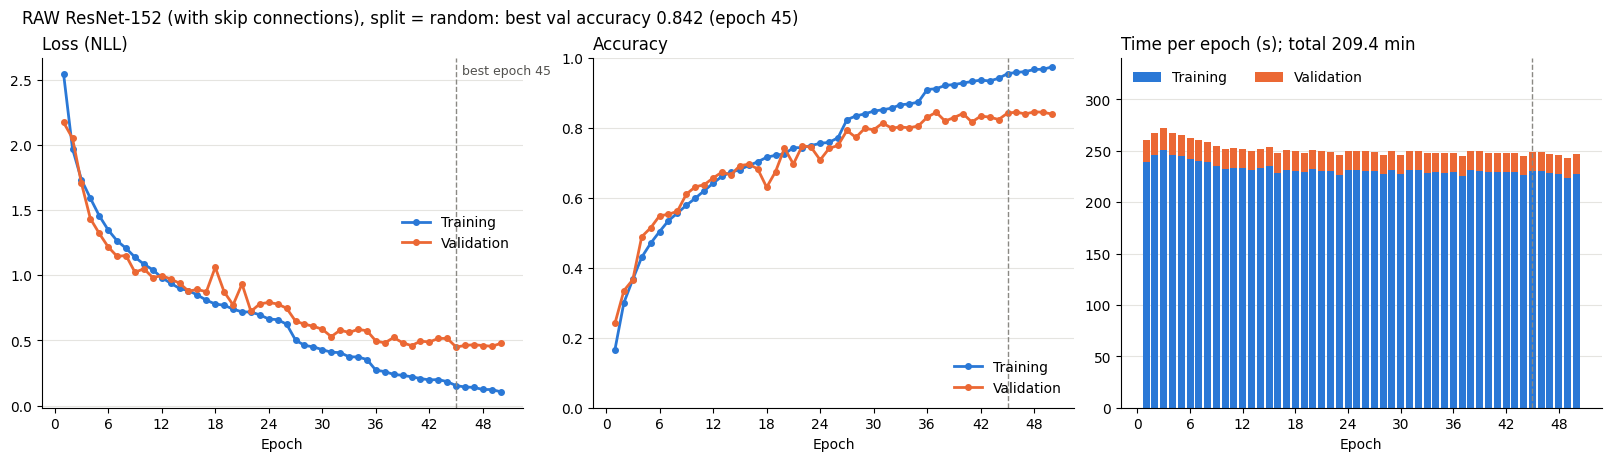

In [11]:
ep = np.array([h["epoch"] for h in history])
COLORS = {"train": "#2a78d6", "val": "#eb6834"}
NAMES = {"train": "Training", "val": "Validation"}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)
for ax, metric, title in [(axes[0], "loss", "Loss (NLL)"), (axes[1], "acc", "Accuracy")]:
    for s in ["train", "val"]:
        ax.plot(ep, [h[f"{s}_{metric}"] for h in history], color=COLORS[s], lw=2,
                marker="o", ms=4, label=NAMES[s])
    ax.set_title(title, loc="left")
axes[1].set_ylim(0, 1)
axes[2].bar(ep, [h["train_s"] for h in history], color="#2a78d6", width=0.8, label="Training")
axes[2].bar(ep, [h["val_s"] for h in history], bottom=[h["train_s"] for h in history],
            color="#eb6834", width=0.8, label="Validation")
axes[2].set_title(f"Time per epoch (s); total {total_time / 60:.1f} min", loc="left")
axes[2].set_ylim(0, 1.25 * max(h["train_s"] + h["val_s"] for h in history))       # headroom for the legend
for ax in axes:
    ax.axvline(best_epoch, color="#8a8984", ls="--", lw=1)
    ax.set_xlabel("Epoch")
    ax.grid(axis="y", color="#e5e4e0", lw=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
for ax, loc in zip(axes, ["center right", "lower right", "upper left"]):
    ax.legend(frameon=False, loc=loc, ncol=3 if ax is axes[2] else 1)
axes[0].annotate(f"best epoch {best_epoch}", (best_epoch, axes[0].get_ylim()[1]),
                 xytext=(4, -12), textcoords="offset points", color="#52514e", fontsize=9)
skips = "with skip connections" if USE_SKIP_CONNECTIONS else "no skip connections"
fig.suptitle(f"{REPRESENTATION.upper()} ResNet-152 ({skips}), split = {SPLIT}: "
             f"best val accuracy {best['val_acc']:.3f} (epoch {best_epoch})", x=0.01, ha="left")
fig.savefig(CURVES_PATH, dpi=150)
plt.show()

## 6. Save the trained model

The trained model is saved in two files, both made with `torch.save` and both storing every weight, bias and BatchNorm running mean/variance:

| File | What it stores | Load with | Use for |
|---|---|---|---|
| `*_state_dict.pt` | the learned **weights and biases** (plus BatchNorm running statistics) from the best-validation epoch, as a `state_dict` (tensors by layer name) | `model.load_state_dict(torch.load(path, weights_only=True))` | **testing elsewhere** and inference: the model PyTorch recommends saving |
| `*_checkpoint.pt` | latest-epoch weights, best weights (`best_state`), optimizer, LR scheduler, AMP scaler, epoch, history, shuffling RNG | `torch.load(path, weights_only=True)`, then `load_state_dict` on each part | **resuming training** after a Colab disconnect |

Both are written during training (Section 4). Loading either needs the `ResNet152` and `Bottleneck` classes from Section 3, built with the same `USE_SKIP_CONNECTIONS` setting. This cell adds the files the evaluation code needs:

- `*_split.npz`: the train, validation and **test** row indices into the dataset file. Evaluate on `test`.
- `*_normalization.npz`: the training-set statistics. Test data (and any new data) must be preprocessed and normalised exactly as during training: mV → `(x − mean_mV) / std_mV` per channel.
- `*_info.json`: model settings, whether skip connections were used, training time and best validation results. It contains no test results.

The training curves were already saved in Section 5 (`*_curves.png`, `*_history.csv`).

In [12]:
np.savez(NORM_PATH, **inputs.norm)
np.savez(SPLIT_PATH, **split)
info = dict(run_name=RUN_NAME, representation=REPRESENTATION, dataset_file=DATA_FILE, input_shape=INPUT_SHAPE, model=MODEL_NAME,
               architecture="ResNet-152 v1.5", skip_connections=USE_SKIP_CONNECTIONS,
               resnet_layers=RESNET_LAYERS, resnet_widths=RESNET_WIDTHS, n_classes=N_CLASSES,
               split=SPLIT, test_fraction=TEST_FRACTION, val_fraction=VAL_FRACTION,
               n_train=len(split["train"]), n_val=len(split["val"]), n_test=len(split["test"]),
               min_epochs=MIN_EPOCHS, max_epochs=MAX_EPOCHS, patience=PATIENCE, batch_size=BATCH_SIZE,
               lr=LR, weight_decay=WEIGHT_DECAY, amp=USE_AMP, seed=SEED, device=str(device) + gpu,
               epochs_run=len(history), best_epoch=best_epoch, best_val_loss=best["val_loss"],
               best_val_acc=best["val_acc"], best_train_loss=best["train_loss"], best_train_acc=best["train_acc"],
               total_time_s=total_time, train_time_s=train_time, mean_epoch_train_s=train_time / len(history),
               files={k: p.name for k, p in dict(state_dict=STATE_PATH, checkpoint=CKPT_PATH, history=HISTORY_PATH,
                                                  curves=CURVES_PATH, normalization=NORM_PATH, split=SPLIT_PATH).items()})
INFO_PATH.write_text(json.dumps(info, indent=2))

print(f"saved in {RUN_DIR}:")
for path in [STATE_PATH, CKPT_PATH, HISTORY_PATH, CURVES_PATH, NORM_PATH, SPLIT_PATH, INFO_PATH]:
    print(f"  {path.name:<55} {path.stat().st_size / 1e6:7.2f} MB" if path.exists() else f"  {path.name:<55} (missing)")

saved in /content/drive/MyDrive/WaveGrip/CNN/runs/raw_random_resnet152:
  raw_random_resnet152_state_dict.pt                       233.60 MB
  raw_random_resnet152_checkpoint.pt                       933.05 MB
  raw_random_resnet152_history.csv                           0.01 MB
  raw_random_resnet152_curves.png                            0.13 MB
  raw_random_resnet152_normalization.npz                     0.00 MB
  raw_random_resnet152_split.npz                             0.12 MB
  raw_random_resnet152_info.json                             0.00 MB


## 7. Load the saved model

`load_trained(source)` rebuilds the model from `*_state_dict.pt` (`"state_dict"`) or from the best weights inside `*_checkpoint.pt` (`"checkpoint"`). The check below loads both and confirms that each gives exactly the same outputs as the trained model on a batch of **validation** trials, so the test set stays untouched. To load a run elsewhere, use the same `ResNet152`/`Bottleneck` code with the run's `USE_SKIP_CONNECTIONS` setting (stored in `*_info.json`).

In [13]:
def load_trained(source="state_dict", run_dir=RUN_DIR):
    # Returns the ResNet-152 in eval mode on the CPU; output = log-probabilities (B, 17)
    m = build_model()
    if source == "state_dict":
        m.load_state_dict(torch.load(run_dir / f"{RUN_NAME}_state_dict.pt", map_location="cpu", weights_only=True))
    elif source == "checkpoint":
        ckpt = torch.load(run_dir / f"{RUN_NAME}_checkpoint.pt", map_location="cpu", weights_only=True)
        m.load_state_dict(ckpt["best_state"])      # ckpt["model"] holds the last epoch's weights instead
    else:
        raise ValueError(f"unknown source {source!r}")
    return m.eval()


reference_model = build_model()
reference_model.load_state_dict(best_state)
reference_model.eval()
x_val, _ = next(iterate_batches(split_t["val"], 16))
x_val = x_val.float().cpu().contiguous()
with torch.no_grad():
    reference = reference_model(x_val)
    for source in ["state_dict", "checkpoint"]:
        out = load_trained(source)(x_val)
        print(f"{source:>10}: max |difference| vs trained model {(out - reference).abs().max():.2e}, "
              f"predictions match: {bool((out.argmax(1) == reference.argmax(1)).all())}")
print("probabilities of the first validation trial:", np.round(reference[0].exp().numpy(), 3))

state_dict: max |difference| vs trained model 0.00e+00, predictions match: True
checkpoint: max |difference| vs trained model 0.00e+00, predictions match: True
probabilities of the first validation trial: [0.41  0.    0.    0.009 0.    0.    0.122 0.    0.032 0.    0.    0.001
 0.    0.    0.    0.425 0.   ]
